# Training of the YOLO pose parking spot detection

Alternative to `train_parking_net.ipynb`: trains a YOLO pose network of [Ultralytics](https://docs.ultralytics.com/tasks/pose/) on the same CVAT annotations. Every parking spot is one object (class + bounding box) with its **four corners as keypoints**.

Expected data: one or more datasets, each with CVAT exports **"CVAT for images 1.1"** (`annotations*.xml`) and one folder of images per rosbag:

```text
data/dataset_v5/
├── annotations.xml
└── rosbag2_2026_10_28-13_32_53/
    ├── rosbag2_2026_10_28-13_32_53_000000.png
    └── ...
```

Steps:
1. Load the CVAT annotations of all datasets and split them into training and validation
2. Export them to the YOLO pose format (`data/yolo/<dataset>/`)
3. Train with Ultralytics (runs are saved in `runs/pose/`)
4. Test on the validation images
5. Copy the best model to `models/yolo_pose.pt` for the `parking_perception_node` (`detector: 'yolo_pose'` in `config/model.yaml`)

Requirements: `pip install -r ../requirements-yolo.txt`

## 1. Import Libraries

In [1]:
import random
import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import ultralytics
from ultralytics import YOLO

# Import the parking package without sourcing the ROS workspace
PACKAGE_DIR = Path.cwd().parent
sys.path.insert(0, str(PACKAGE_DIR))

from parking.training.dataset import (  # noqa: E402
    bag_name,
    cvat_labels,
    load_cvat_xml,
    split_by_blocks,
)
from parking.training.yolo_export import export_yolo_pose  # noqa: E402

print("Ultralytics version:", ultralytics.__version__)
if torch.cuda.is_available():
    print("Using GPU:", torch.cuda.get_device_name(0))
    DEVICE = 0
elif torch.backends.mps.is_available():
    print("Using Apple GPU (MPS). If the training fails, set DEVICE = 'cpu'.")
    DEVICE = "mps"
else:
    print("No GPU found, using CPU instead.")
    DEVICE = "cpu"

Ultralytics version: 8.4.193
Using Apple GPU (MPS). If the training fails, set DEVICE = 'cpu'.


## 2. Data Loading and Export

All datasets in `DATA_DIRS` are combined. They have to come from the same CVAT project (same labels).

Consecutive frames of a rosbag are almost identical. Therefore every rosbag is cut into blocks of `BLOCK_SIZE` consecutive frames and a random part of the blocks **of every rosbag** is used for the validation. So every rosbag and maneuver (driving past, parking in) is in the training and in the validation. The corners are sorted into the fixed order bottom-left, bottom-right, top-right, top-left, so the keypoints have the same meaning in every parking spot.

In [2]:
DATA_DIRS = [
    PACKAGE_DIR / "data" / "dataset_v4",  # Driving past the parking spots
    PACKAGE_DIR / "data" / "dataset_v5",  # Also parking into two 90 degree spots
]
DATASET_NAME = "_".join(d.name.removeprefix("dataset_") for d in DATA_DIRS)
YOLO_DIR = PACKAGE_DIR / "data" / "yolo" / f"dataset_{DATASET_NAME}"
VAL_FRACTION = 0.2
BLOCK_SIZE = 10  # Consecutive images per block (10 images = 50 frames of the rosbag)
SEED = 42

XML_FILES = {d: sorted(d.glob("annotations*.xml")) for d in DATA_DIRS}
for data_dir, files in XML_FILES.items():
    print(f"{data_dir.name}:", [f.name for f in files])
    if not files:
        raise FileNotFoundError(f"No annotations*.xml in {data_dir}")

# All tasks have to belong to the same CVAT project, i.e. have the same labels
all_files = [f for files in XML_FILES.values() for f in files]
CLASSES = cvat_labels(all_files[0])
for xml_file in all_files[1:]:
    if cvat_labels(xml_file) != CLASSES:
        raise ValueError(f"Different labels in {xml_file}")
print("Classes:", CLASSES)

samples = [
    s
    for data_dir, files in XML_FILES.items()
    for f in files
    for s in load_cvat_xml(f, data_dir, CLASSES)
]
print(f"{len(samples)} images, {sum(len(s.spots) for s in samples)} parking spots")
for class_id, name in enumerate(CLASSES):
    count = sum(a.class_id == class_id for s in samples for a in s.spots)
    print(f"  {name}: {count}")

# Every image may only appear once (e.g. the same rosbag in two datasets)
names = [s.image_path.name for s in samples]
duplicates = {n for n in names if names.count(n) > 1}
if duplicates:
    raise ValueError(f"Images in several datasets, e.g. {sorted(duplicates)[:3]}")

train_samples, val_samples = split_by_blocks(samples, VAL_FRACTION, BLOCK_SIZE, SEED)
for bag in sorted({bag_name(s) for s in samples}):
    num_train = sum(bag_name(s) == bag for s in train_samples)
    num_val = sum(bag_name(s) == bag for s in val_samples)
    print(f"  {bag}: train {num_train}, val {num_val}")
print(f"Train: {len(train_samples)} images, validation: {len(val_samples)} images")

DATA_YAML = export_yolo_pose({"train": train_samples, "val": val_samples}, CLASSES, YOLO_DIR)
print("Exported to", DATA_YAML)
print(DATA_YAML.read_text())

dataset_v4: ['annotations.xml']
dataset_v5: ['annotations.xml']
Classes: ['Parking_90_free', 'Parking_90_besetzt', 'Parking_90_gesperrt', 'Parking_Parallel_Frei', 'Parking_Parallel_Besetzt', 'Parking_Parallel_Gesperrt']
335 images, 905 parking spots
  Parking_90_free: 412
  Parking_90_besetzt: 165
  Parking_90_gesperrt: 0
  Parking_Parallel_Frei: 164
  Parking_Parallel_Besetzt: 59
  Parking_Parallel_Gesperrt: 105
  rosbag2_2026_10_28-13_32_18: train 94, val 30
  rosbag2_2026_10_28-13_32_53: train 171, val 40
Train: 265 images, validation: 70 images
Exported to /Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/data/yolo/dataset_v4_v5/data.yaml
path: /Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/data/yolo/dataset_v4_v5
train: images/train
val: images/val
kpt_shape:
- 4
- 3
flip_idx:
- 1
- 0
- 3
- 2
names:
  0: Parking_90_free
  1: Parking_90_besetzt
  2: Parking_90_gesperrt
  3: Parking_Parall

## 3. Training

Starts from a model pretrained on COCO keypoints (downloaded automatically). `n` is the smallest and fastest model, `s` is more accurate but about 3x slower on the vehicle.

Important augmentation: **`fliplr=0.0`**. On the track 90° parking spots are only on the left and parallel ones only on the right, a mirrored image would teach the network wrong combinations.

Ultralytics shows the progress and saves the curves, metrics and example images in `runs/pose/<name>/`. The training stops early if the validation metric does not improve for `patience` epochs.

In [3]:
BASE_MODEL = "yolo11n-pose.pt"  # or yolo11s-pose.pt
IMAGE_SIZE = 640  # The BEV image (800x640) is scaled to 640 on the long side
EPOCHS = 30
BATCH_SIZE = 8
RUN_NAME = f"parking_{DATASET_NAME}"

model = YOLO(BASE_MODEL)
model.train(
    data=str(DATA_YAML),
    imgsz=IMAGE_SIZE,
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    patience=30,
    device=DEVICE,
    workers=4,
    seed=SEED,
    project=str(PACKAGE_DIR / "runs" / "pose"),
    name=RUN_NAME,
    exist_ok=True,
    # Augmentation
    fliplr=0.0,  # Never mirror (side of the road matters)
    hsv_h=0.0,  # Grayscale images, no hue/saturation
    hsv_s=0.0,
    hsv_v=0.4,  # Brightness
    degrees=5.0,  # Small rotations
    mosaic=1.0,
    close_mosaic=10,  # No mosaic in the last epochs
)
RUN_DIR = Path(model.trainer.save_dir)
print("Run saved to", RUN_DIR)

Ultralytics 8.4.193 🚀 Python-3.14.6 torch-2.15.0 MPS (Apple M5 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/data/yolo/dataset_v4_v5/data.yaml, degrees=5.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-pose.pt, momentum=0.937, mosaic

/Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://

       1/30      2.29G      1.654      6.477     0.6901      3.646      1.875         11        640: 100% ━━━━━━━━━━━━ 34/34 1.7it/s 19.7s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.7it/s 1.8s0.3ss
                   all         70        177       0.71      0.202      0.172      0.104          0          0          0          0

      Epoch    GPU_mem   box_loss  pose_loss  kobj_loss   cls_loss   dfl_loss  Instances       Size
       2/30      2.38G      1.352      5.595     0.6562      2.941      1.614         47        640: 0% ──────────── 0/34  0.6s

/Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://

       2/30      2.42G      1.309      5.268     0.6672      2.613      1.529          6        640: 100% ━━━━━━━━━━━━ 34/34 3.9it/s 8.6s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 3.6it/s 1.4s0.3s
                   all         70        177      0.365      0.382      0.297      0.175      0.484      0.101     0.0869     0.0242

      Epoch    GPU_mem   box_loss  pose_loss  kobj_loss   cls_loss   dfl_loss  Instances       Size
       3/30      3.33G      1.241      4.786      0.655      2.408      1.527         48        640: 0% ──────────── 0/34  0.7s

...

      28/30      3.31G     0.6913     0.5255     0.4177     0.6615     0.9794          0        640: 100% ━━━━━━━━━━━━ 34/34 4.1it/s 8.4s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 4.1it/s 1.2s0.3s
                   all         70        177      0.971      0.877       0.97      0.738      0.962       0.87      0.954      0.813

      Epoch    GPU_mem   box_loss  pose_loss  kobj_loss   cls_loss   dfl_loss  Instances       Size
      29/30      3.38G      0.732     0.5303     0.3364     0.5253     0.8815         17        640: 0% ──────────── 0/34  0.6s

/Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://

      29/30      3.31G     0.6891     0.5762     0.4097     0.5287     0.9858          3        640: 100% ━━━━━━━━━━━━ 34/34 4.2it/s 8.1s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 4.1it/s 1.2s0.3s
                   all         70        177      0.968       0.92      0.972      0.737       0.96      0.911      0.956      0.828

      Epoch    GPU_mem   box_loss  pose_loss  kobj_loss   cls_loss   dfl_loss  Instances       Size
      30/30      2.37G     0.7356     0.7573     0.4046     0.5462     0.9934         21        640: 0% ──────────── 0/34  0.6s

/Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://

      30/30      3.29G     0.6882     0.5512     0.4199     0.5177      0.987          4        640: 100% ━━━━━━━━━━━━ 34/34 4.1it/s 8.2s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 3.6it/s 1.4s0.3s
                   all         70        177       0.97      0.926       0.98      0.749      0.962      0.917      0.964      0.842

30 epochs completed in 0.089 hours.
Optimizer stripped from /Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/runs/pose/parking_v4_v5/weights/last.pt, 5.6MB
Optimizer stripped from /Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/runs/pose/parking_v4_v5/weights/best.pt, 5.6MB

Validating /Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/runs/pose/parking_v4_v5/weights/best.pt...
Ultralytics 8.4.193 🚀 Python-3

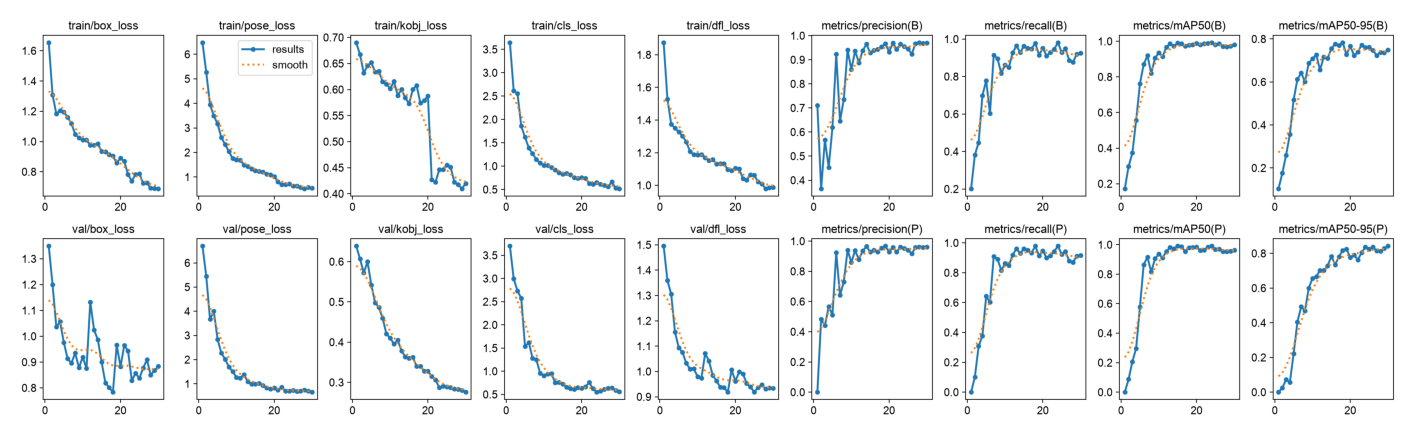

In [4]:
# Training curves of Ultralytics (losses, precision, recall, mAP of boxes and keypoints)
plt.figure(figsize=(18, 9))
plt.imshow(plt.imread(RUN_DIR / "results.png"))
plt.axis("off")
plt.show()

## 4. Testing

Validates the best model (`mAP50-95(P)` is the metric of the keypoints, `(B)` of the boxes) and draws the predictions (green, blue dot: first corner = bottom-left) and the annotations (red) into the validation images.

In [5]:
SCORE_THRESHOLD = 0.3

best_model = YOLO(RUN_DIR / "weights" / "best.pt")
metrics = best_model.val(data=str(DATA_YAML), imgsz=IMAGE_SIZE, device=DEVICE, plots=False)
print(f"Box mAP50: {metrics.box.map50:.3f}, keypoint mAP50: {metrics.pose.map50:.3f}")

Ultralytics 8.4.193 🚀 Python-3.14.6 torch-2.15.0 MPS (Apple M5 Pro)
YOLO11n-pose summary (fused): 109 layers, 2,655,454 parameters, 0 gradients, 6.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3648.5±711.0 MB/s, size: 138.6 KB)
val: Scanning /Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/data/yolo/dataset_v4_v5/labels/val.cache... 70 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 70/70 73.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 6.1it/s 0.8s0.2s
                   all         70        177      0.953      0.978       0.98      0.783      0.953      0.978      0.979      0.816
       Parking_90_free         38         71      0.853       0.98       0.93      0.754      0.853       0.98      0.929      0.734
    Parking_90_besetzt         40         40      0.977       0.95      0.983      0.775  

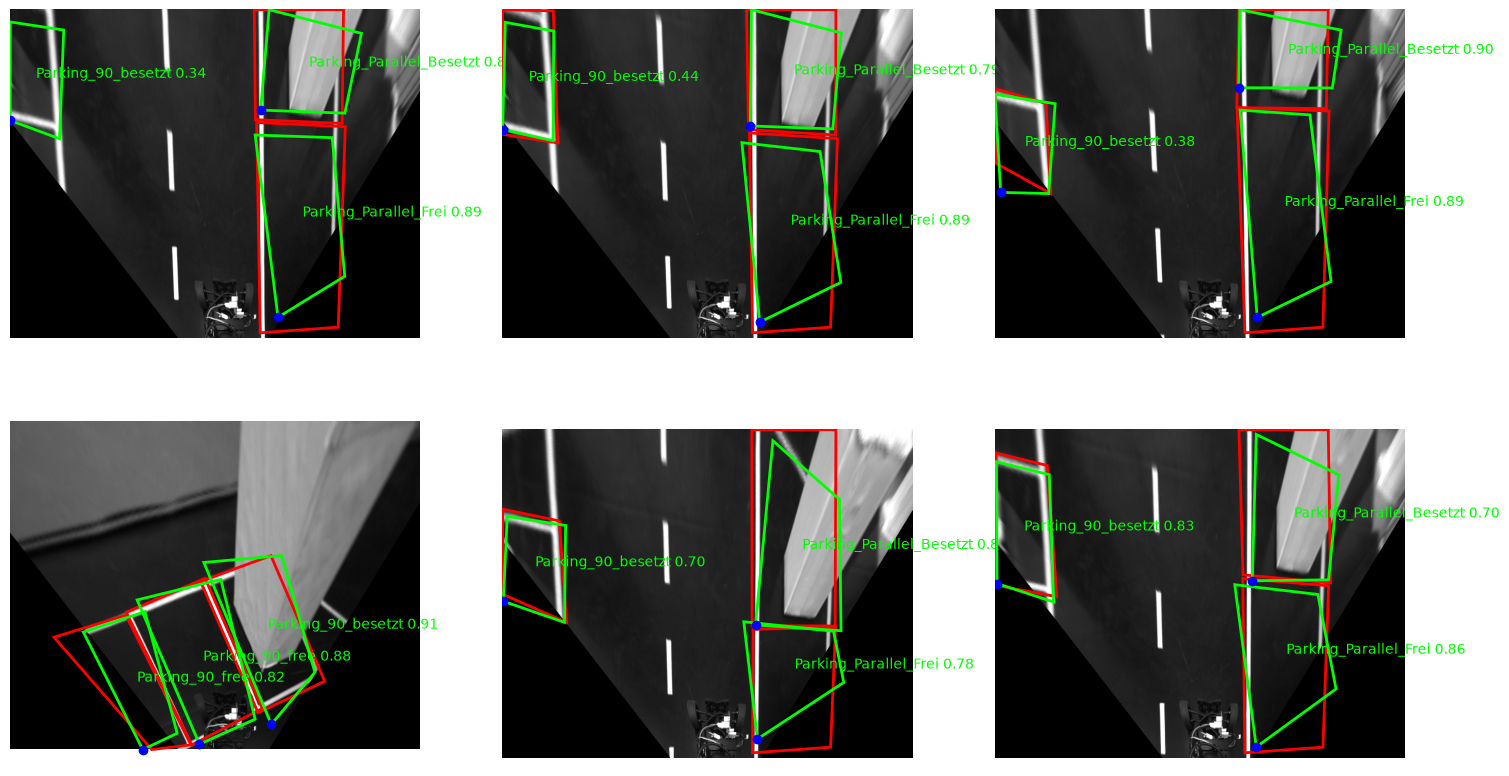

In [6]:
num_images = min(6, len(val_samples))
rows = (num_images + 2) // 3
fig, axes = plt.subplots(rows, 3, figsize=(18, 5 * rows), squeeze=False)
for ax in axes.flat:
    ax.axis("off")

for idx, sample in enumerate(random.sample(val_samples, num_images)):
    result = best_model.predict(str(sample.image_path), imgsz=IMAGE_SIZE, conf=SCORE_THRESHOLD, verbose=False)[0]

    ax = axes.flat[idx]
    ax.imshow(plt.imread(sample.image_path), cmap="gray")
    for annotation in sample.spots:
        ax.fill(*annotation.corners.T, edgecolor="red", fill=False, linewidth=2)

    if result.keypoints is None:
        continue
    for class_id, score, corners in zip(
        result.boxes.cls.int().tolist(), result.boxes.conf.tolist(), result.keypoints.xy.cpu().numpy()
    ):
        ax.fill(*corners.T, edgecolor="lime", fill=False, linewidth=2)
        ax.plot(*corners[0], "o", color="blue")
        ax.text(*corners.mean(axis=0), f"{CLASSES[class_id]} {score:.2f}", color="lime")
plt.show()

## 5. Save the Model for the Node

Copies the best model to `models/yolo_pose.pt`. The installed package links to this file (`colcon build --symlink-install`), so restarting the `parking_perception_node` is enough.

In [7]:
MODEL_PATH = PACKAGE_DIR / "models" / "yolo_pose.pt"
shutil.copy2(RUN_DIR / "weights" / "best.pt", MODEL_PATH)
print("Saved model to", MODEL_PATH)

Saved model to /Users/ruvenbraun/Desktop/01_Studium/SmartRollerz/smarty_workspace/smarty_workspace/src/parking/models/yolo_pose.pt
